# County-Level Cancer Incidence & Lifestyle/Risk-Factor Clustering

**Author:** Michael Luttman
**Purpose:** Portfolio project exploring whether U.S. counties cluster into distinct risk profiles when combining cancer incidence data with publicly available lifestyle, behavioral, and healthcare-access indicators.

**This is an exploratory, educational analysis — not a clinical or causal study.** See the Limitations & Ethics section at the end before drawing any conclusions.

## Data Sources
1. **Cancer incidence by county** — [NCI State Cancer Profiles](https://statecancerprofiles.cancer.gov/incidencerates/) (public, no login required)
2. **County-level lifestyle & health indicators** — [CDC PLACES](https://www.cdc.gov/places/) (obesity, physical inactivity, smoking, binge drinking, diabetes, high blood pressure, general health, healthcare access), via the public Socrata API at `data.cdc.gov`

## Method
Standardize features → unsupervised clustering (K-Means) → profile and visualize the resulting county clusters → compare cluster membership against cancer incidence rates.


## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import requests
import io
import csv
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)


## 2. Pull lifestyle / risk-factor data (CDC PLACES)

This hits the public CDC Socrata API directly (`data.cdc.gov`) and pulls only the columns we need, for every U.S. county. No API key or login required.

If this cell ever fails (CDC occasionally changes dataset IDs on new annual releases), go to https://data.cdc.gov/browse?q=PLACES%20County%20Data and search for the current "PLACES: County Data (GIS Friendly Format)" release — it will give you a new dataset ID (the part of the URL that looks like `i46a-9kgh`) to swap in below.

In [2]:
PLACES_DATASET_ID = "i46a-9kgh"  # PLACES County Data, GIS-friendly format

fields = [
    "countyfips", "countyname", "statedesc", "totalpopulation",
    "obesity_crudeprev", "lpa_crudeprev", "csmoking_crudeprev",
    "binge_crudeprev", "diabetes_crudeprev", "bphigh_crudeprev",
    "ghlth_crudeprev", "access2_crudeprev",
]

url = (
    f"https://data.cdc.gov/resource/{PLACES_DATASET_ID}.csv"
    f"?$select={','.join(fields)}"
    f"&$limit=5000"
)

resp = requests.get(url, timeout=60)
resp.raise_for_status()
places = pd.read_csv(io.StringIO(resp.text))
print(places.shape)
places.head()


(3143, 12)


,countyfips,countyname,statedesc,totalpopulation,obesity_crudeprev,lpa_crudeprev,csmoking_crudeprev,binge_crudeprev,diabetes_crudeprev,bphigh_crudeprev,ghlth_crudeprev,access2_crudeprev
0,21221,Trigg,Kentucky,14369,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,21231,Wayne,Kentucky,19580,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,21229,Washington,Kentucky,12267,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,42099,Perry,Pennsylvania,46083,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,42121,Venango,Pennsylvania,49431,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Pull cancer incidence data (NCI State Cancer Profiles)

This pulls age-adjusted invasive cancer incidence rates (all cancer sites, both sexes, all races, 2018–2022 average — the latest stable period at time of writing) for every U.S. county.

**If the request below fails or returns an error page** (this site occasionally blocks automated requests depending on where Colab's IP is routed that day), use the manual fallback:
1. Go to https://statecancerprofiles.cancer.gov/incidencerates/index.php?stateFIPS=00&areatype=county&cancer=001&race=00&sex=0&age=001&stage=999&year=0&type=incd
2. Click the **Export** / CSV download option near the top of the data table
3. Upload the downloaded CSV into this Colab session (folder icon on the left → upload) and point `cancer_csv_path` at it instead of fetching live.

In [3]:
CANCER_URL = (
    "https://statecancerprofiles.cancer.gov/incidencerates/index.php"
    "?stateFIPS=00&areatype=county&cancer=001&race=00&sex=0"
    "&age=001&stage=999&year=0&type=incd"
    "&sortVariableName=rate&sortOrder=default&output=1"
)

cancer_csv_path = None  # set to a local path (e.g. "data/cancer_incidence.csv") if you use the manual fallback above

def parse_state_cancer_profiles_csv(raw_text: str) -> pd.DataFrame:
    """State Cancer Profiles exports have several metadata/footnote lines
    before AND after the actual data table, with inconsistent field counts,
    which breaks a naive pd.read_csv. We locate the real header line by
    looking for a row that contains both a "County" and a "FIPS" column,
    then parse only the well-formed data rows beneath it, stopping at the
    first row that no longer looks like data (e.g. a footnote block)."""
    lines = raw_text.splitlines()

    header_idx = None
    for i, line in enumerate(lines):
        if re.search(r'"?county"?', line, re.IGNORECASE) and re.search(r'"?fips"?', line, re.IGNORECASE):
            header_idx = i
            break
    if header_idx is None:
        raise ValueError("Could not locate a header row containing 'County' and 'FIPS' in the response.")

    header = next(csv.reader([lines[header_idx]]))
    n_cols = len(header)

    data_rows = []
    for line in lines[header_idx + 1:]:
        if not line.strip():
            continue
        row = next(csv.reader([line]))
        if len(row) != n_cols:
            # First malformed row after the table = footnotes; stop there.
            break
        data_rows.append(row)

    return pd.DataFrame(data_rows, columns=header)


try:
    if cancer_csv_path:
        raise FileNotFoundError  # force manual path below if set
    resp = requests.get(CANCER_URL, timeout=60, headers={"User-Agent": "Mozilla/5.0"})
    resp.raise_for_status()
    cancer = parse_state_cancer_profiles_csv(resp.text)
    if cancer.empty:
        raise ValueError("Parsed 0 data rows \u2014 export format may have changed.")
except Exception as e:
    if cancer_csv_path:
        print(f"Using manual file: {cancer_csv_path}")
        cancer = pd.read_csv(cancer_csv_path)
    else:
        raise RuntimeError(
            "Live fetch/parse of cancer incidence data failed "
            f"({type(e).__name__}: {e}).\n\n"
            "Use the manual fallback described above:\n"
            "1. Visit the CANCER_URL printed below in a browser (drop the "
            "&output=1 to see the page, or keep it to trigger a CSV download)\n"
            "2. Save the file into this notebook's environment, e.g. "
            "data/cancer_incidence.csv (in Colab: folder icon on the left \u2192 upload)\n"
            "3. Set cancer_csv_path = \"data/cancer_incidence.csv\" above and re-run this cell\n\n"
            f"URL: {CANCER_URL}"
        ) from e

print(cancer.shape)
cancer.head()


(3145, 14)


,County,FIPS,2023 Rural-Urban Continuum Codes([rural urban note]),"Age-Adjusted Incidence Rate([rate note]) - cases per 100,000",Lower 95% Confidence Interval,Upper 95% Confidence Interval,CI*Rank([rank note]),Lower CI (CI*Rank),Upper CI (CI*Rank),Average Annual Count,Recent Trend,Recent 5-Year Trend ([trend note]) in Incidence Rates,Lower 95% Confidence Interval,Upper 95% Confidence Interval
0,US (SEER+NPCR)(1),00000,N/A,453.4,453.1,453.7,N/A,N/A,N/A,1872272,falling,-0.6,-1.0,-0.2
1,"Union County, Florida(2)",12125,Rural,1229.6,1159.3,1303.4,N/A,N/A,N/A,240,stable,0.3,-0.4,1.1
2,"Hudspeth County, Texas(7)",48229,Urban,842.1,698.5,1007.7,N/A,N/A,N/A,25,rising,15.1,11.2,24.2
3,"Dewey County, South Dakota(2)",46041,Rural,713.7,599.1,843,N/A,N/A,N/A,30,rising,2.1,0.1,4.2
4,"Polk County, Texas(7)",48373,Rural,693.1,660.4,727,N/A,N/A,N/A,448,stable,-1.4,-3.3,1.4


## 4. Clean & standardize

Cancer incidence data typically comes with footnote markers, suppressed values (fewer than 16 cases), and a trailing "FIPS" column we need to align with PLACES' `countyfips`. We clean both sides and join on the 5-digit county FIPS code.

In [4]:
# --- Clean PLACES ---
places = places.drop_duplicates(subset="countyfips").copy()
places["countyfips"] = places["countyfips"].astype(str).str.zfill(5)

# --- Clean cancer incidence ---
# Column names vary slightly by export version; inspect and adapt as needed:
print(cancer.columns.tolist())


['County', 'FIPS', '2023 Rural-Urban Continuum Codes([rural urban note])', 'Age-Adjusted Incidence Rate([rate note]) - cases per 100,000', 'Lower 95% Confidence Interval', 'Upper 95% Confidence Interval', 'CI*Rank([rank note])', 'Lower CI (CI*Rank)', 'Upper CI (CI*Rank)', 'Average Annual Count', 'Recent Trend', 'Recent 5-Year Trend ([trend note]) in Incidence Rates', 'Lower 95% Confidence Interval', 'Upper 95% Confidence Interval']


In [5]:
# Expect something like: 'County', 'FIPS', 'Age-Adjusted Incidence Rate([rate note]) - cases per 100,000'
# Rename to standard names once you've confirmed the actual column labels from the cell above.
rate_col = [c for c in cancer.columns if "Rate" in c and "Trend" not in c][0]
fips_col = [c for c in cancer.columns if "FIPS" in c][0]

cancer_clean = cancer[[fips_col, rate_col]].rename(
    columns={fips_col: "countyfips", rate_col: "cancer_incidence_rate"}
)
cancer_clean["countyfips"] = cancer_clean["countyfips"].astype(str).str.zfill(5)

# Drop suppressed / non-numeric rates (e.g. "* ", "data not available")
cancer_clean["cancer_incidence_rate"] = pd.to_numeric(
    cancer_clean["cancer_incidence_rate"], errors="coerce"
)
cancer_clean = cancer_clean.dropna(subset=["cancer_incidence_rate"])
cancer_clean = cancer_clean.drop_duplicates(subset="countyfips")

print(cancer_clean.shape)
cancer_clean.head()


(3133, 2)


,countyfips,cancer_incidence_rate
0,00000,453.4
1,12125,1229.6
2,48229,842.1
3,46041,713.7
4,48373,693.1


In [6]:
# --- Join ---
df = places.merge(cancer_clean, on="countyfips", how="inner")
print(f"Joined dataset: {df.shape[0]} counties, {df.shape[1]} columns")
df.head()


Joined dataset: 3122 counties, 13 columns


,countyfips,countyname,statedesc,totalpopulation,obesity_crudeprev,lpa_crudeprev,csmoking_crudeprev,binge_crudeprev,diabetes_crudeprev,bphigh_crudeprev,ghlth_crudeprev,access2_crudeprev,cancer_incidence_rate
0,21221,Trigg,Kentucky,14369,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,512.4
1,21231,Wayne,Kentucky,19580,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,539.0
2,21229,Washington,Kentucky,12267,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,552.6
3,42099,Perry,Pennsylvania,46083,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,480.0
4,42121,Venango,Pennsylvania,49431,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,494.7


## 5. Exploratory data analysis

Counties with complete data: 2935


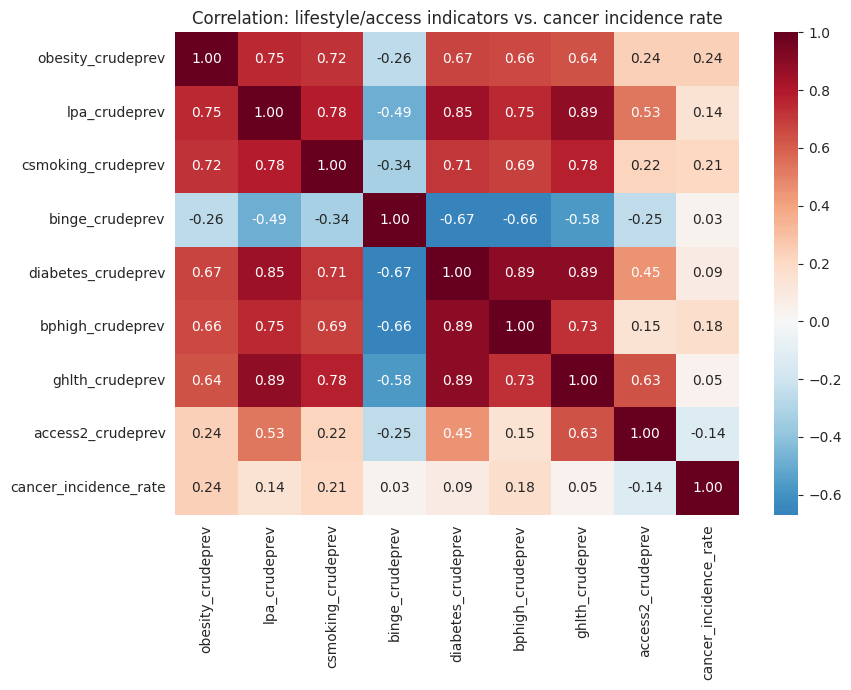

In [7]:
feature_cols = [
    "obesity_crudeprev", "lpa_crudeprev", "csmoking_crudeprev",
    "binge_crudeprev", "diabetes_crudeprev", "bphigh_crudeprev",
    "ghlth_crudeprev", "access2_crudeprev",
]

df_model = df.dropna(subset=feature_cols + ["cancer_incidence_rate"]).copy()
print(f"Counties with complete data: {len(df_model)}")

corr = df_model[feature_cols + ["cancer_incidence_rate"]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation: lifestyle/access indicators vs. cancer incidence rate")
plt.tight_layout()
plt.show()


## 6. Clustering

Standardize the lifestyle/risk-factor features (not cancer rate itself — we want to see how cancer incidence *varies across* clusters built from lifestyle data, not build clusters directly from the outcome) and run K-Means. Use the elbow method + silhouette score to pick *k*.

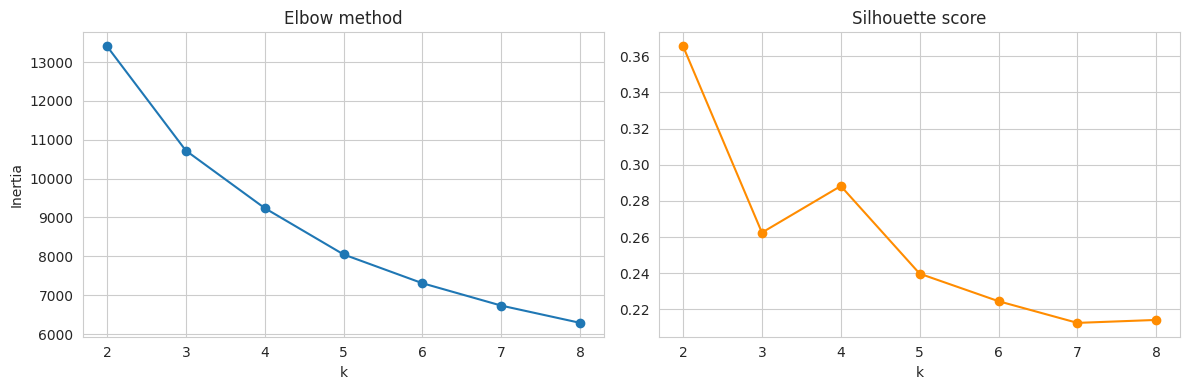

In [8]:
X = df_model[feature_cols].values
X_scaled = StandardScaler().fit_transform(X)

inertias, sil_scores = [], []
k_range = range(2, 9)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_range), inertias, marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(k_range), sil_scores, marker="o", color="darkorange")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.show()


In [9]:
# Pick k based on the plots above (update this after inspecting the elbow/silhouette results)
K = 4

kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
df_model["cluster"] = kmeans.fit_predict(X_scaled)

df_model["cluster"].value_counts().sort_index()


,count
cluster,
0,674
1,195
2,1367
3,699


## 7. Cluster profiles

What does each cluster actually look like, and how does cancer incidence differ across them?

In [10]:
profile = df_model.groupby("cluster")[feature_cols + ["cancer_incidence_rate"]].mean().round(1)
profile["n_counties"] = df_model["cluster"].value_counts().sort_index()
profile


,obesity_crudeprev,lpa_crudeprev,csmoking_crudeprev,binge_crudeprev,diabetes_crudeprev,bphigh_crudeprev,ghlth_crudeprev,access2_crudeprev,cancer_incidence_rate,n_counties
cluster,,,,,,,,,,
0,31.9,21.9,12.0,17.0,10.5,32.7,16.9,8.7,444.4,674
1,38.4,33.6,15.3,15.7,15.3,37.0,27.6,23.7,430.7,195
2,37.8,27.7,15.7,16.1,13.2,38.5,20.8,9.8,465.4,1367
3,41.8,34.9,20.0,13.4,17.1,45.5,27.7,12.6,475.3,699


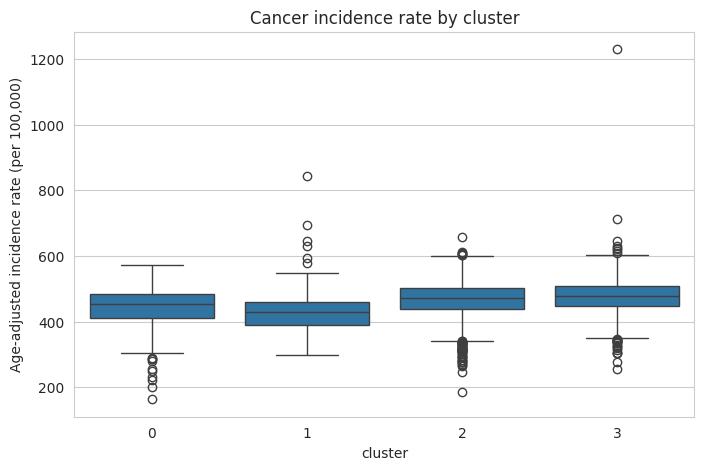

In [11]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_model, x="cluster", y="cancer_incidence_rate")
plt.title("Cancer incidence rate by cluster")
plt.ylabel("Age-adjusted incidence rate (per 100,000)")
plt.show()


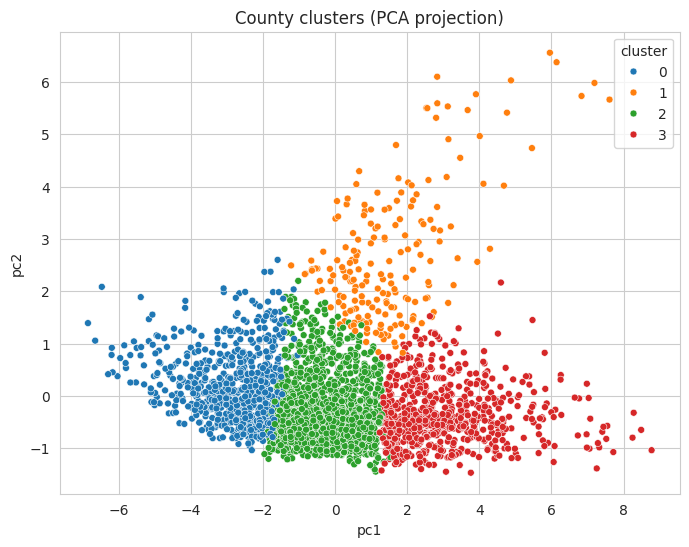

Variance explained by PC1+PC2: 80.0%


In [12]:
# 2D visualization via PCA, for intuition only (not used for clustering itself)
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)
df_model["pc1"], df_model["pc2"] = coords[:, 0], coords[:, 1]

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_model, x="pc1", y="pc2", hue="cluster", palette="tab10", s=25)
plt.title("County clusters (PCA projection)")
plt.show()

print(f"Variance explained by PC1+PC2: {pca.explained_variance_ratio_.sum():.1%}")


In [13]:
# Highest and lowest cancer-incidence counties, for spot-checking
df_model.sort_values("cancer_incidence_rate", ascending=False)[
    ["countyname", "statedesc", "cluster", "cancer_incidence_rate"] + feature_cols
].head(10)


,countyname,statedesc,cluster,cancer_incidence_rate,obesity_crudeprev,lpa_crudeprev,csmoking_crudeprev,binge_crudeprev,diabetes_crudeprev,bphigh_crudeprev,ghlth_crudeprev,access2_crudeprev
219,Union,Florida,3,1229.6,41.6,30.7,20.1,16.1,14.5,41.0,25.7,17.3
714,Hudspeth,Texas,1,842.1,41.0,38.5,18.7,18.5,14.3,33.0,33.2,38.6
1740,Dewey,South Dakota,3,713.7,43.6,36.3,29.5,17.9,18.0,38.1,29.9,13.4
1936,Polk,Texas,1,693.1,39.2,32.4,18.9,16.5,15.4,40.7,26.5,17.3
2027,Haakon,South Dakota,2,659.0,33.7,26.8,15.7,16.2,13.5,38.0,18.6,8.5
2230,Esmeralda,Nevada,3,644.9,36.1,32.3,18.2,12.6,17.7,44.8,29.9,14.7
1013,Briscoe,Texas,1,644.4,39.5,34.5,16.8,14.5,17.5,43.4,29.0,20.5
1723,McMullen,Texas,1,630.5,38.6,35.5,15.9,15.0,17.8,42.1,28.7,22.3
890,Carter,Missouri,3,629.5,40.0,37.0,22.6,14.7,15.7,43.3,28.4,10.9
392,Issaquena,Mississippi,3,624.0,45.3,41.0,21.6,13.9,16.4,46.1,32.2,21.3


In [14]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=feature_cols,
    columns=["PC1", "PC2"]
).round(2)

loadings

,PC1,PC2
obesity_crudeprev,0.33,-0.25
lpa_crudeprev,0.40,0.08
csmoking_crudeprev,0.36,-0.24
binge_crudeprev,-0.28,0.01
diabetes_crudeprev,0.41,-0.01
bphigh_crudeprev,0.38,-0.34
ghlth_crudeprev,0.41,0.22
access2_crudeprev,0.21,0.85


## 8. Limitations & ethics — read before drawing conclusions

- **This is an ecological (county-level) analysis, not an individual-level one.** A county with high smoking rates and high cancer incidence does not mean the specific people who smoke are the ones who got cancer — this is the well-known "ecological fallacy." Individual-level causal claims cannot be made from this data.
- **Correlation is not causation.** Clusters and correlations shown here can reflect confounders this analysis doesn't control for: age distribution, screening/diagnosis rates (areas with better healthcare access often show *higher* recorded incidence simply because more cancers are caught), income, insurance coverage, occupational exposures, and local environmental factors not included here.
- **PLACES indicators are themselves model-based small-area estimates**, not direct county-level surveys — CDC derives them from BRFSS survey responses using statistical modeling, so they carry their own estimation uncertainty.
- **Cancer incidence rates can be suppressed or unstable in low-population counties** (CDC/NCI suppress rates based on small case counts for privacy and statistical reliability); this analysis drops those rows, which may bias the remaining sample toward larger, more urban counties.
- **This project is for educational/portfolio purposes.** It is not epidemiological research, has not been peer reviewed, and should not inform any individual's health decisions or be cited as evidence of what causes cancer in any population.

## 9. Possible next steps
- Pull multiple years of PLACES data and look at trends over time, not just a single snapshot
- Add EPA environmental quality data (air/water quality index) by county
- Add TCGA tumor-level genomic data for a complementary, individual (not ecological) analysis
- Try hierarchical clustering or a Gaussian mixture model and compare cluster assignments to K-Means
- Control for age distribution and screening rates where that data is available, to reduce confounding

## 10. Analysis
Counties with worse lifestyle habits don't show dramatically higher cancer rates in this data — which either means lifestyle isn't the main driver at the county level, or (more likely) healthcare access and screening rates are muddying the picture.  Clustering isn't just separating "healthy vs. unhealthy" counties — it's separating along two genuinely different dimensions: overall lifestyle risk (PC1), and healthcare access (PC2). And that cluster 1 — high access barriers but not the worst lifestyle — is the same group that earlier had the lowest cancer incidence rate, which strengthens the under-diagnosis theory from before: that group may simply have fewer people getting screened and diagnosed, not fewer people actually getting cancer.
